# IMDB Movie Reviews Dataset
## Sentiment Analysis and Text Classification using this Dataset

## Dataset Description

*This dataset contains movie reviews along with their associated binary sentiment polarity labels.The core dataset contains 50,000 reviews split evenly into 25k train and 25k test sets. The overall distribution of labels is balanced (25k pos and 25k neg).*


*In the entire collection, no more than 30 reviews are allowed for any given movie because reviews for the same movie tend to have correlated ratings. Further, the train and test sets contain a disjoint set of movies, so no significant performance is obtained by memorizing movie-unique terms and their associated with observed labels. In the labeled train/test sets, a negative review has a score <= 4 out of 10, and a positive review has a score >= 7 out of 10. Thus reviews with more neutral ratings are not included in the train/test sets.*

# Importing Dependencies

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
pd.set_option('display.max_columns', 100) # Show all columns when looking at dataframe
import warnings
warnings.filterwarnings('ignore') # remove warnings from the notebook
import matplotlib
from IPython.display import Math, HTML

# Importing Data

*The Dataset is publicly available at [Kaggle](https://www.kaggle.com/iarunava/imdb-movie-reviews-dataset).*

*To get the Dataset we will use Kaggle API and will download it directly to our working Directory.*

*To do this You need to first get your Kaggle API Token and for that you need to have a kaggle account.*

*1. Go to kaggle.com/ and open your user settings page.*

![Users_login](https://i.stack.imgur.com/jxGQv.png)

*2. Next, scroll down to the API access section and click generate to download an API key.*

![API_token](https://i.stack.imgur.com/Hzlhp.png)

*Now this will download a Kaggle.json file, place it in the current working directory and follow along.*

In [0]:
!pip install -q kaggle # install Kaggle API

In [0]:
# Move the kaggle.json file into ~/.kaggle
!mkdir -p ~/.kaggle 
!cp kaggle.json ~/.kaggle/

*Now go the kaggle [Page](https://www.kaggle.com/iarunava/imdb-movie-reviews-dataset) and just copy the API Command and run it.*

In [4]:
!kaggle datasets download -d iarunava/imdb-movie-reviews-dataset

imdb-movie-reviews-dataset.zip: Skipping, found more recently modified local copy (use --force to force download)


*Now do a !ls to check if it is downloaded and is in current working directory*

In [5]:
!ls

aclImdb  imdb-movie-reviews-dataset.zip  kaggle.json  sample_data


In [0]:
# Unzipping the file
from zipfile import ZipFile
zip = ZipFile('imdb-movie-reviews-dataset.zip')
zip.extractall()

*It would have extracted a folder called aclimdb, lets change the working directory to aclimdb*


In [0]:
import os
os.chdir('/content/aclImdb')

In [8]:
!ls

imdbEr.txt  imdb.vocab	README	test  train


In [0]:
# Getting the positive Train Data
train_pos_list= list()
import glob
train_pos = '/content/aclImdb/train/pos/*.txt'
pos_files = glob.glob(train_pos)
for name in pos_files:
    with open(name) as f:
        train_pos_list.append(f.read())

# Getting the Negative Train Data
train_neg_list= list()
train_neg = '/content/aclImdb/train/neg/*.txt'
neg_files = glob.glob(train_neg)
for name in neg_files:
    with open(name) as f:
        train_neg_list.append(f.read())

# creating a DataFrame out of it
train_y= (['Positive'] * len(train_pos_list)) + (['Negative'] * len(train_neg_list))
train_x= train_pos_list
train_x.extend(train_neg_list)
train= pd.DataFrame({'reviews' : train_x, 
                     'Label': train_y})

In [0]:
# Getting the positive Test Data
test_pos_list= list()
import glob
test_pos = '/content/aclImdb/test/pos/*.txt'
pos_files = glob.glob(test_pos)
for name in pos_files:
    with open(name) as f:
        test_pos_list.append(f.read())

# Getting the Negative Test Data
test_neg_list= list()
test_neg = '/content/aclImdb/train/neg/*.txt'
neg_files = glob.glob(test_neg)
for name in neg_files:
    with open(name) as f:
        test_neg_list.append(f.read())

# creating a DataFrame out of it
test_y= (['Positive'] * len(test_pos_list)) + (['Negative'] * len(test_neg_list))
test_x= test_pos_list
test_x.extend(test_neg_list)
test= pd.DataFrame({'reviews' : test_x, 
                     'Label': test_y})

In [11]:
train.head()

,reviews,Label
0,"Back in the day of the big studio system, the ...",Positive
1,I'm gonna tip the scales here a bit and say I ...,Positive
2,Lavish production values and solid performance...,Positive
3,I think that this film was one of Kurt Russels...,Positive
4,me and my sister saw the premiere last night.....,Positive


In [12]:
test.head()

,reviews,Label
0,I have to confess that I know some of those in...,Positive
1,Why has Ramón(Carlos Fuentes)brought his five ...,Positive
2,This movie is quite better than the first one ...,Positive
3,"I enjoyed the film very much, especially the p...",Positive
4,This show came to Canada via PBS in the mid 90...,Positive


In [13]:
train.shape, test.shape

((25000, 2), (25000, 2))

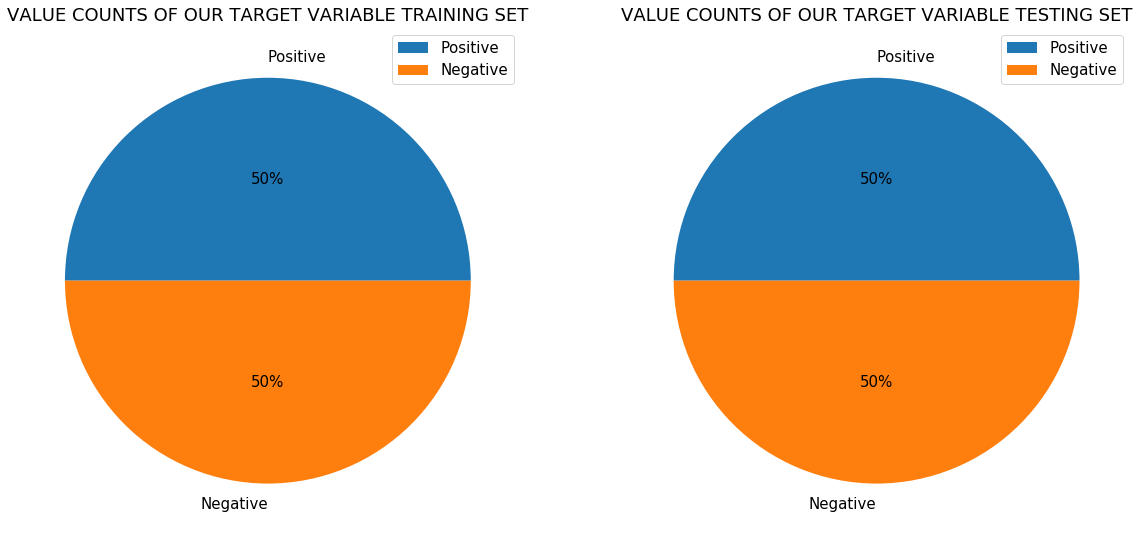

In [14]:
font = {'family' : 'normal',
        'size'   : 15}
matplotlib.rc('font', **font) # this changes the size and weight of the labels in our plot
fig, (ax1, ax2) = plt.subplots(1, 2 ,figsize=(20,15))
ax1.pie(train.Label.value_counts().to_list(), labels=train.Label.value_counts().index.to_list(), autopct='%1.0f%%', pctdistance=.5, labeldistance=1.1) # pctdistance and labeldistance is to change the position of the labels and the values
ax1.legend( loc = 'upper right')
ax1.title.set_text("VALUE COUNTS OF OUR TARGET VARIABLE TRAINING SET")
ax2.pie(test.Label.value_counts().to_list(), labels=test.Label.value_counts().index.to_list(), autopct='%1.0f%%', pctdistance=.5, labeldistance=1.1) # pctdistance and labeldistance is to change the position of the labels and the values
ax2.legend( loc = 'upper right')
ax2.title.set_text("VALUE COUNTS OF OUR TARGET VARIABLE TESTING SET")
plt.show();

*So there are around 12500 positive and 12500 negative values both training and test set.*

In [0]:
# suffle train and test
from sklearn.utils import shuffle
train = shuffle(train)
test = shuffle(test)
train= train.reset_index(drop= True)
test= test.reset_index(drop= True)

In [16]:
train.head()

,reviews,Label
0,I thought Hugh O'Conor was astounding as the y...,Positive
1,THE DEVIL'S PLAYTHING is my second attempt at ...,Positive
2,This is a low budget film with a cast of unkno...,Positive
3,Kimi wa petto is a cute story about a girl who...,Positive
4,This film has good characters with excellent p...,Positive


In [17]:
test.head()

,reviews,Label
0,I just finished watching Marigold today and I'...,Positive
1,This interesting film noir features three very...,Positive
2,"In Hollywood in the 1930's and 1940's, I think...",Negative
3,For the sake of propaganda during World War II...,Positive
4,I guess it's Jack's great empathic ability tha...,Negative


# Basic Text Preprocessing

In [18]:
# Check for the existence of NaN values in a cell:
train.isnull().sum()

reviews    0
Label      0
dtype: int64

In [19]:
# Detect & remove empty strings
blanks = []  # start with an empty list

for i,lb,rv in train.itertuples():  # iterate over the DataFrame
    if type(rv)==str:            # avoid NaN values
        if rv.isspace():         # test 'review' for whitespace
            blanks.append(i)     # add matching index numbers to the list
        
print(len(blanks), 'blanks: ', blanks)

0 blanks:  []


## Sentence Length

In [0]:
def get_stats(column):
    pos= train.loc[train.Label == 'Positive', column].describe()
    neg= train.loc[train.Label == 'Negative', column].describe()
    data= pd.DataFrame({"Positive": list(pos), "Negative": list(neg)}, index=train[column].describe().index)
    return data

In [0]:
train['Word_Count'] = [len(review.split()) for review in train['reviews']]

In [22]:
get_stats('Word_Count')

,Positive,Negative
count,12500.000000,12500.000000
mean,236.706560,230.867840
std,180.485743,166.663126
min,12.000000,10.000000
25%,125.000000,128.000000
50%,174.000000,174.000000
75%,291.000000,278.000000
max,2470.000000,1522.000000


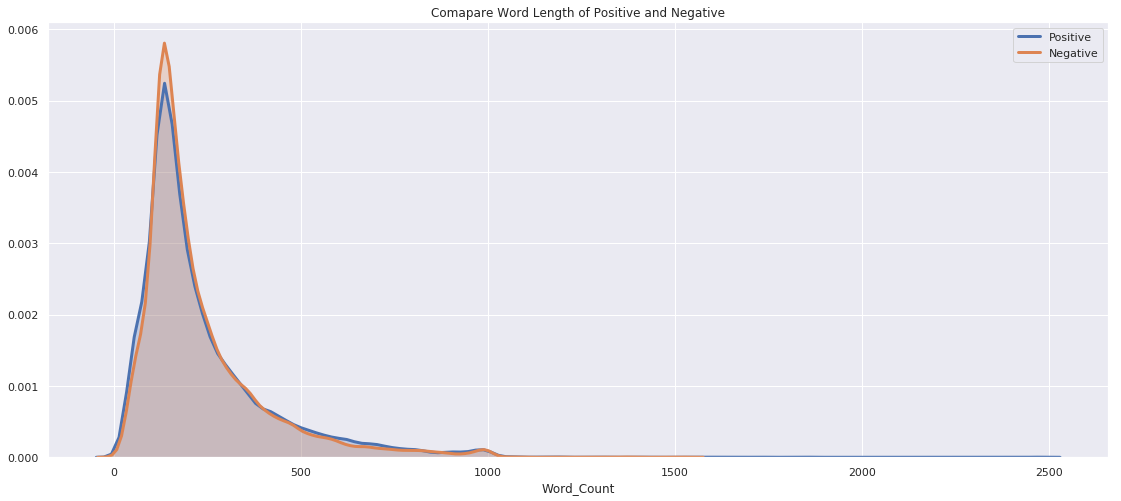

In [23]:
sns.set()
data1= train.loc[train.Label == 'Positive', 'Word_Count']
data2= train.loc[train.Label == 'Negative', 'Word_Count']
fig = plt.figure(figsize=(19, 8))
sns.distplot(data1, hist = False, kde = True, 
                 kde_kws = {'shade': True, 'linewidth': 3}, 
                 label= 'Positive')
sns.distplot(data2, hist = False, kde = True,
                 kde_kws = {'shade': True, 'linewidth': 3}, 
                 label= 'Negative')
plt.title("Comapare Word Length of Positive and Negative");

*There is not much difference in word length but the max value for some Positive Reviews are higher because, may be some people got very excited after the twisting Climax of Movie and didn't stopped writing or may be after a emotional ending to the story some girl with a misty eye wrote a very long comment.*🤣  🤣

## Capitalization

In [0]:
train['upper_case'] = [sum(char.isupper() for char in review) for review in train['reviews']]

In [25]:
get_stats('upper_case')

,Positive,Negative
count,12500.000000,12500.000000
mean,37.370320,34.880800
std,36.479239,32.471106
min,0.000000,0.000000
25%,16.000000,16.000000
50%,26.000000,25.000000
75%,46.000000,43.000000
max,673.000000,749.000000


*Not much diffrence for the positive and negative reviews.*

## Usage of punctuation

In [0]:
import string
train['punctuation'] = [sum(char in string.punctuation for char in review) for review in train['reviews']] 

In [27]:
get_stats('punctuation')

,Positive,Negative
count,12500.000000,12500.000000
mean,52.187040,54.012880
std,44.222677,44.331114
min,0.000000,1.000000
25%,23.000000,25.000000
50%,38.000000,41.000000
75%,68.000000,68.000000
max,543.000000,475.000000


*IQR is same in both, but max value is higher for positive reviews.*

*Dig in more and check why there is more number a exclamation mark in a single comment.*

In [0]:
from collections import Counter
from nltk.corpus import stopwords

def getMostCommonWords(reviews, n_most_common, stopwords=None):

    # flatten review column into a list of words, and set each to lowercase
    flattened_reviews = [word for review in reviews for word in  review.lower().split()]


    # remove punctuation from reviews
    flattened_reviews = [''.join(char for char in review if char not in string.punctuation) for review in flattened_reviews]


    # remove stopwords, if applicable
    if stopwords:
        flattened_reviews = [word for word in flattened_reviews if word not in stopwords]

    # remove any empty strings that were created by this process
    flattened_reviews = [review for review in flattened_reviews if review]

    return Counter(flattened_reviews).most_common(n_most_common)

In [0]:
positive_reviews= train.loc[train.Label == 'Positive', 'reviews']
negative_reviews= train.loc[train.Label == 'Negative', 'reviews']

In [30]:
# Top twenty words in positve reviews with stopwords
getMostCommonWords(positive_reviews, 20)

[('the', 172264),
 ('and', 88785),
 ('a', 83135),
 ('of', 76586),
 ('to', 66391),
 ('is', 57026),
 ('in', 49708),
 ('it', 38435),
 ('i', 35574),
 ('this', 34739),
 ('that', 34052),
 ('br', 27534),
 ('as', 26157),
 ('with', 23139),
 ('for', 22273),
 ('was', 21833),
 ('but', 20414),
 ('film', 19592),
 ('movie', 18140),
 ('his', 17152)]

In [31]:
# Top twenty words in positve reviews without stopwords
getMostCommonWords(positive_reviews, 20, stopwords.words('english'))

[('br', 27534),
 ('film', 19592),
 ('movie', 18140),
 ('one', 13069),
 ('like', 8729),
 ('good', 7396),
 ('story', 6485),
 ('great', 6293),
 ('time', 5999),
 ('see', 5845),
 ('well', 5568),
 ('also', 5506),
 ('really', 5450),
 ('would', 5289),
 ('even', 4898),
 ('first', 4620),
 ('much', 4606),
 ('people', 4312),
 ('films', 4264),
 ('get', 4230)]

In [32]:
# Top twenty words in negative reviews with stopwords 
getMostCommonWords(negative_reviews, 20)

[('the', 162427),
 ('a', 78805),
 ('and', 73443),
 ('of', 68740),
 ('to', 68651),
 ('is', 49829),
 ('in', 43320),
 ('this', 40451),
 ('i', 40145),
 ('it', 38664),
 ('that', 35300),
 ('br', 29609),
 ('was', 26175),
 ('movie', 23667),
 ('for', 21691),
 ('but', 21325),
 ('with', 20732),
 ('as', 20505),
 ('film', 17863),
 ('on', 16859)]

In [33]:
# Top twenty words in negative reviews with stopwords 
getMostCommonWords(negative_reviews, 20, stopwords.words('english'))

[('br', 29609),
 ('movie', 23667),
 ('film', 17863),
 ('one', 12439),
 ('like', 10912),
 ('even', 7605),
 ('good', 7159),
 ('bad', 7082),
 ('would', 6846),
 ('really', 6213),
 ('time', 5780),
 ('see', 5378),
 ('dont', 5163),
 ('get', 4982),
 ('much', 4978),
 ('story', 4969),
 ('people', 4639),
 ('could', 4550),
 ('make', 4546),
 ('made', 4342)]

*Right away, we can spot a few differences, such as the heavy use of terms like "good", "great" in the positive class, and words like "dont" and "bad" in place in the negative class. Additionally, if you increase the value of the n_most_common parameter in our function, you can see words like "not" (which nltk's corpus classifies as a stopword).*

In [34]:
np.array(stopwords.words('english'))

array(['i', 'me', 'my', 'myself', 'we', 'our', 'ours', 'ourselves', 'you',
       "you're", "you've", "you'll", "you'd", 'your', 'yours', 'yourself',
       'yourselves', 'he', 'him', 'his', 'himself', 'she', "she's", 'her',
       'hers', 'herself', 'it', "it's", 'its', 'itself', 'they', 'them',
       'their', 'theirs', 'themselves', 'what', 'which', 'who', 'whom',
       'this', 'that', "that'll", 'these', 'those', 'am', 'is', 'are',
       'was', 'were', 'be', 'been', 'being', 'have', 'has', 'had',
       'having', 'do', 'does', 'did', 'doing', 'a', 'an', 'the', 'and',
       'but', 'if', 'or', 'because', 'as', 'until', 'while', 'of', 'at',
       'by', 'for', 'with', 'about', 'against', 'between', 'into',
       'through', 'during', 'before', 'after', 'above', 'below', 'to',
       'from', 'up', 'down', 'in', 'out', 'on', 'off', 'over', 'under',
       'again', 'further', 'then', 'once', 'here', 'there', 'when',
       'where', 'why', 'how', 'all', 'any', 'both', 'each', 'few', 'm

*If we look into the 'english' stopwords, there are words like 'not', "wasn't" and others which can come frequently in Negative Reviews, so we cant remove all the stopwords from the text.*



In [0]:
import string
import re
from nltk.tokenize import word_tokenize
TAG_RE = re.compile(r'<[^>]+>') # remove <br> and other html tags

def clean_text(text):
    # lower text
    text = text.lower()

    # Reemove Html Tags like <br>
    text= TAG_RE.sub('', text)

    # remove puncutation
    text = text.translate(str.maketrans('', '', string.punctuation))

    # tokenize_text
    text = [word for word in word_tokenize(text)]

    # remove words that contain numbers
    text = [word for word in text if not any(c.isdigit() for c in word)]
    
    # remove empty tokens
    text = [t for t in text if len(t) > 0]

    # remove words with only one letter
    text = [t for t in text if len(t) > 1]

    # join all
    text = " ".join(text)
    return(text)

In [0]:
train["reviews_clean"] = train["reviews"].apply(lambda x: clean_text(x))

In [0]:
test["reviews_clean"] = test["reviews"].apply(lambda x: clean_text(x))

In [38]:
train[["reviews_clean", "reviews"]][:20]

,reviews_clean,reviews
0,thought hugh oconor was astounding as the youn...,I thought Hugh O'Conor was astounding as the y...
1,the devils plaything is my second attempt at j...,THE DEVIL'S PLAYTHING is my second attempt at ...
2,this is low budget film with cast of unknowns ...,This is a low budget film with a cast of unkno...
3,kimi wa petto is cute story about girl who one...,Kimi wa petto is a cute story about a girl who...
4,this film has good characters with excellent p...,This film has good characters with excellent p...
5,had absolutely nothing to do the past weekend ...,I had absolutely nothing to do the past weeken...
6,this is an abysmal piece of storytelling it is...,This is an abysmal piece of story-telling. It ...
7,this film is basically two hours of dafoes cha...,This film is basically two hours of Dafoe's ch...
8,citizen is the superbly told true story of the...,"""Citizen X"" is the superbly told true story of..."
9,the teasers for tree of palme try to pass it o...,The teasers for Tree of Palme try to pass it o...


In [39]:
test[["reviews_clean", "reviews"]][:20]

,reviews_clean,reviews
0,just finished watching marigold today and ill ...,I just finished watching Marigold today and I'...
1,this interesting film noir features three very...,This interesting film noir features three very...
2,in hollywood in the and think that every studi...,"In Hollywood in the 1930's and 1940's, I think..."
3,for the sake of propaganda during world war ii...,For the sake of propaganda during World War II...
4,guess its jacks great empathic ability that ma...,I guess it's Jack's great empathic ability tha...
5,before give spike lees mess of film summer of ...,Before I give Spike Lee's mess of a film SUMME...
6,disney has yet to meet movie it couldnt make a...,Disney has yet to meet a movie it couldn't mak...
7,wonder how someone could diss on this movie it...,I wonder how someone could diss on this movie....
8,renee zellweger is betty kansas waitress who w...,"Renee Zellweger is Betty, a Kansas waitress wh..."
9,when got this movie free from my job along wit...,"When i got this movie free from my job, along ..."


*Lets build a Word Cloud on Train and Test Dataset.*

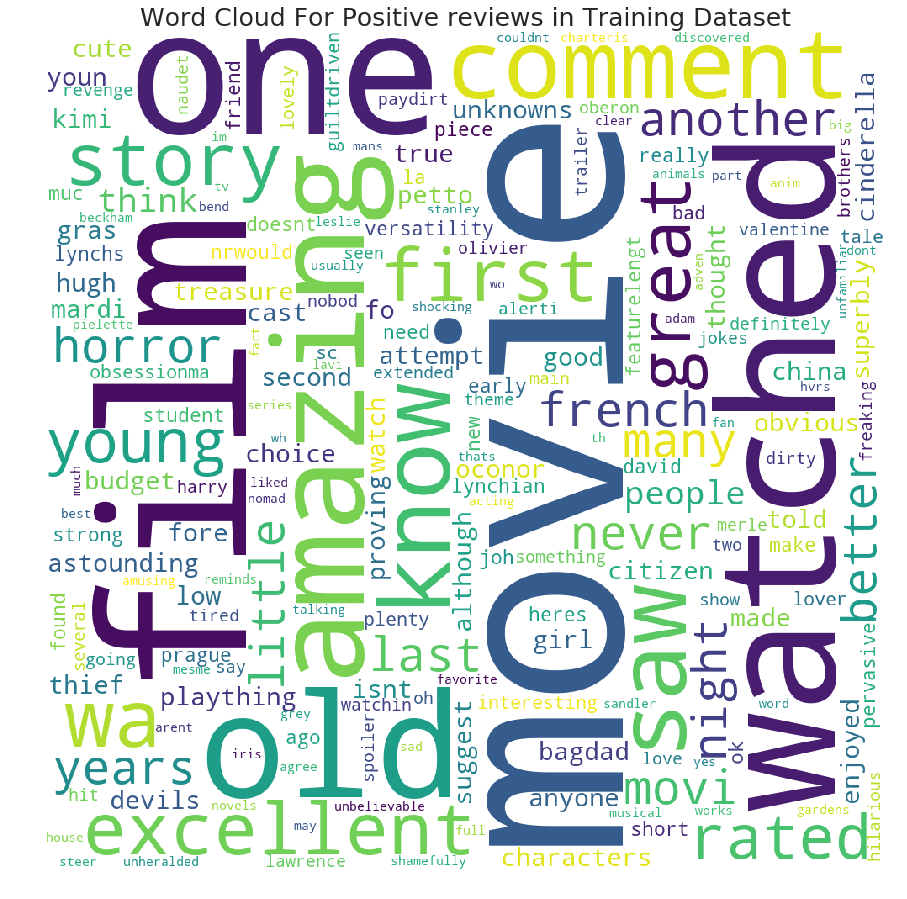

In [40]:
# Python program to generate WordCloud 
  
# importing all necessery modules 
from wordcloud import WordCloud
import matplotlib.pyplot as plt 
import pandas as pd 
   
wordcloud = WordCloud(width = 1000, height = 1000, 
                background_color ='white', 
                min_font_size = 10).generate(str(train.loc[train.Label == 'Positive', 'reviews_clean'])) 
  
# plot the WordCloud image                        
plt.figure(figsize = (19, 12), facecolor = None) 
plt.imshow(wordcloud) 
plt.axis("off") 
plt.tight_layout(pad = 0) 
plt.title("Word Cloud For Positive reviews in Training Dataset", fontdict={'fontsize': 25})
plt.show() 

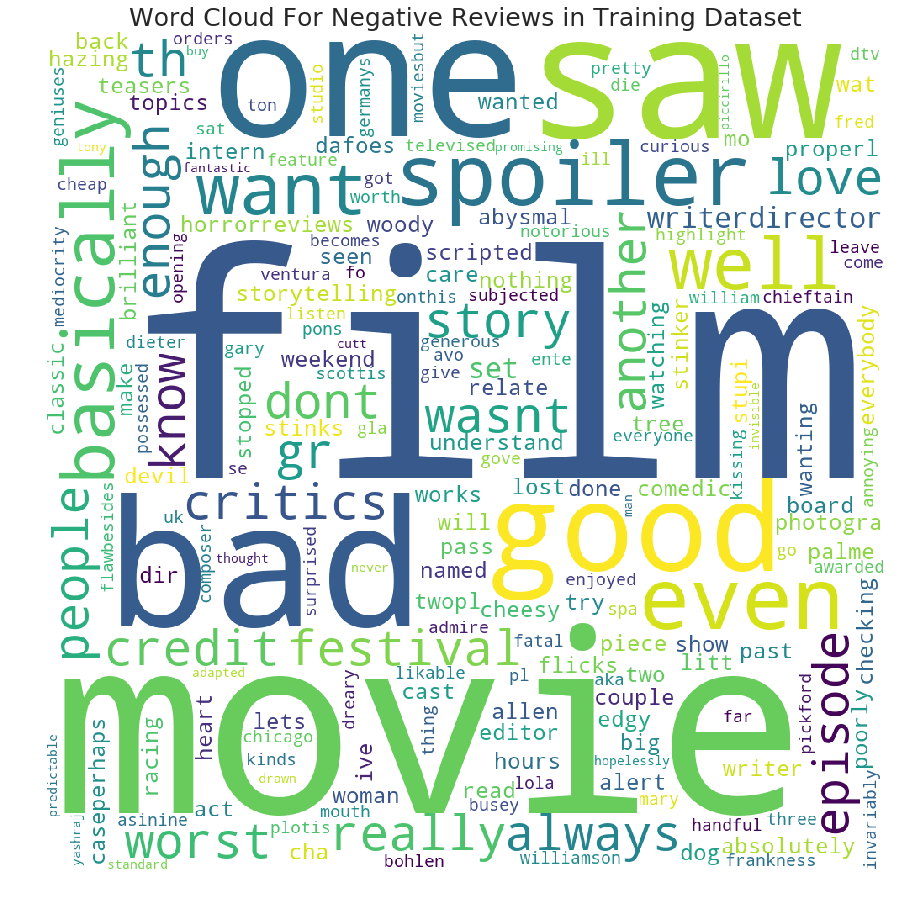

In [41]:
# Python program to generate WordCloud 
  
# importing all necessery modules 
from wordcloud import WordCloud, STOPWORDS 
import matplotlib.pyplot as plt 
import pandas as pd 
   
wordcloud = WordCloud(width = 1000, height = 1000, 
                background_color ='white',  
                min_font_size = 10).generate(str(train.loc[train.Label == 'Negative', 'reviews_clean'])) 
  
# plot the WordCloud image                        
plt.figure(figsize = (19, 12), facecolor = None) 
plt.imshow(wordcloud) 
plt.axis("off") 
plt.tight_layout(pad = 0) 
plt.title("Word Cloud For Negative Reviews in Training Dataset", fontdict={'fontsize': 25})
plt.show() 

# Vectorization

## Word2Vec

In [0]:
from gensim.models import Word2Vec

In [0]:
Bigger_list=[]
for i in train['reviews_clean']:
    li = list(i.split(" "))
    Bigger_list.append(li)	
Model= Word2Vec(Bigger_list, min_count=15, size=5000, sg=0) # Continuous Bag of Words (CBOW) Model, sg=0

In [0]:
# Function to average all word vectors in a paragraph
def featureVecMethod(words, model, num_features):
    # Pre-initialising empty numpy array for speed
    featureVec = np.zeros(num_features,dtype="float32")
    nwords = 0
    
    #Converting Index2Word which is a list to a set for better speed in the execution.
    index2word_set = set(model.wv.index2word)
    
    for word in  words:
        if word in index2word_set:
            nwords = nwords + 1
            featureVec = np.add(featureVec,model[word])
    
    # Dividing the result by number of words to get average
    featureVec = np.divide(featureVec, nwords)
    return featureVec

In [0]:
# Function for calculating the average feature vector
def getAvgFeatureVecs(reviews, model, num_features):
    counter = 0
    reviewFeatureVecs = np.zeros((len(reviews),num_features),dtype="float32")
    for review in reviews:
        # Printing a status message every 1000th review
        if counter%1000 == 0:
            print("Review %d of %d"%(counter,len(reviews)))
            
        reviewFeatureVecs[counter] = featureVecMethod(review, model, 5000)
        counter = counter+1
        
    return reviewFeatureVecs

In [46]:
# Calculating average feature vector for training set
clean_train_reviews = []
for review in train['reviews_clean']:
    clean_train_reviews.append(review.split())
    
trainDataVecs = getAvgFeatureVecs(clean_train_reviews, Model, 5000)

Review 0 of 25000
Review 1000 of 25000
Review 2000 of 25000
Review 3000 of 25000
Review 4000 of 25000
Review 5000 of 25000
Review 6000 of 25000
Review 7000 of 25000
Review 8000 of 25000
Review 9000 of 25000
Review 10000 of 25000
Review 11000 of 25000
Review 12000 of 25000
Review 13000 of 25000
Review 14000 of 25000
Review 15000 of 25000
Review 16000 of 25000
Review 17000 of 25000
Review 18000 of 25000
Review 19000 of 25000
Review 20000 of 25000
Review 21000 of 25000
Review 22000 of 25000
Review 23000 of 25000
Review 24000 of 25000


In [47]:
# Calculating average feature vactors for test set     
clean_test_reviews = []
for review in test['reviews_clean']:
    clean_test_reviews.append(review.split())
    
testDataVecs = getAvgFeatureVecs(clean_test_reviews, Model, 5000)

Review 0 of 25000
Review 1000 of 25000
Review 2000 of 25000
Review 3000 of 25000
Review 4000 of 25000
Review 5000 of 25000
Review 6000 of 25000
Review 7000 of 25000
Review 8000 of 25000
Review 9000 of 25000
Review 10000 of 25000
Review 11000 of 25000
Review 12000 of 25000
Review 13000 of 25000
Review 14000 of 25000
Review 15000 of 25000
Review 16000 of 25000
Review 17000 of 25000
Review 18000 of 25000
Review 19000 of 25000
Review 20000 of 25000
Review 21000 of 25000
Review 22000 of 25000
Review 23000 of 25000
Review 24000 of 25000


In [0]:
X_train= trainDataVecs
y_train= train.Label.map(lambda x: 1 if x=='Positive' else 0)
X_test= testDataVecs
y_test= test.Label.map(lambda x: 1 if x=='Positive' else 0)

# Classifing Positive and Negative Sentiments

# Using SentiWordnet

One of the most straightforward approaches is to use SentiWordnet to compute the polarity of the words and average that value. The plan is to use this model as a baseline for future approaches. It’s also a good idea to know about SentiWordnet and how to use it.

In [0]:
from nltk.stem import WordNetLemmatizer
from nltk.corpus import wordnet as wn
from nltk.corpus import sentiwordnet as swn
from nltk import sent_tokenize, word_tokenize, pos_tag

lemmatizer = WordNetLemmatizer()

def penn_to_wn(tag):
    """
    Convert between the PennTreebank tags to simple Wordnet tags
    """
    if tag.startswith('J'):
        return wn.ADJ
    elif tag.startswith('N'):
        return wn.NOUN
    elif tag.startswith('R'):
        return wn.ADV
    elif tag.startswith('V'):
        return wn.VERB
    return None

def swn_polarity(text):
    sentiment = 0.0
    tokens_count = 0
 
    text = clean_text(text)
 
    raw_sentences = sent_tokenize(text)
    for raw_sentence in raw_sentences:
        tagged_sentence = pos_tag(word_tokenize(raw_sentence))
 
        for word, tag in tagged_sentence:
            wn_tag = penn_to_wn(tag)
            if wn_tag not in (wn.NOUN, wn.ADJ, wn.ADV):
                continue
 
            lemma = lemmatizer.lemmatize(word, pos=wn_tag)
            if not lemma:
                continue
 
            synsets = wn.synsets(lemma, pos=wn_tag)
            if not synsets:
                continue
 
            # Take the first sense, the most common
            synset = synsets[0]
            swn_synset = swn.senti_synset(synset.name())
 
            sentiment += swn_synset.pos_score() - swn_synset.neg_score()
            tokens_count += 1
 
    # judgment call ? Default to positive or negative
    if not tokens_count:
        return 1
 
    # sum greater than 0 => positive sentiment
    if sentiment >= 0:
        return 1
 
    # negative sentiment
    return 0

In [69]:
test.columns

Index(['reviews', 'Label', 'reviews_clean'], dtype='object')

In [78]:
print(swn_polarity(test.reviews[0]), test.Label[0])
print(swn_polarity(test.reviews[1]), test.Label[1])
print(swn_polarity(test.reviews[2]), test.Label[2])
print(swn_polarity(test.reviews[3]), test.Label[3])
print(swn_polarity(test.reviews[4]), test.Label[4])

1 Positive
0 Positive
1 Negative
0 Positive
1 Negative


Let’s compute the accuracy of the SWN method

In [0]:
from sklearn.metrics import accuracy_score
y_pred = [swn_polarity(text) for text in test.reviews]

In [82]:
print(f"SentiWordnet Accuracy: {(accuracy_score(y_test, y_pred) * 100):.2f} %")

SentiWordnet Accuracy: 66.68 %


## Logistic Regression

In [49]:
## Fitting Model to the Training Set
from sklearn.linear_model import LogisticRegression
classifier = LogisticRegression(random_state = 0)
classifier.fit(X_train, y_train)

LogisticRegression(C=1.0, class_weight=None, dual=False, fit_intercept=True,
                   intercept_scaling=1, l1_ratio=None, max_iter=100,
                   multi_class='warn', n_jobs=None, penalty='l2',
                   random_state=0, solver='warn', tol=0.0001, verbose=0,
                   warm_start=False)

In [0]:
# Predicting Test Set
y_pred = classifier.predict(X_test)

In [51]:
# Evaluating Results
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, precision_score, recall_score
cm = confusion_matrix(y_test, y_pred)
acc= accuracy_score(y_test, y_pred)
precision= precision_score(y_test, y_pred) # tp / (tp + fp)
recall= recall_score(y_test, y_pred) # tp / (tp + fn)
f1= f1_score(y_test, y_pred)
print(f"Accuracy : {(acc * 100):.4f} %")

Accuracy : 83.8520 %


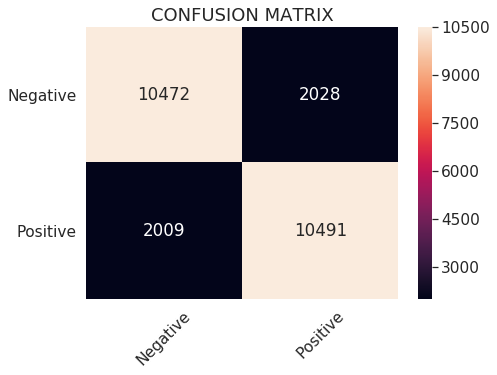

In [52]:
# Printing the Confusion Matrix with test Accuracy
df_cm = pd.DataFrame(cm, index = (0, 1), columns = (0, 1))
plt.figure(figsize = (7,5))
sns.set(font_scale=1.4)
sns.heatmap(df_cm, annot=True, fmt='g', xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
plt.xticks(rotation=45)
plt.yticks(rotation='horizontal')
plt.title("CONFUSION MATRIX", fontsize= 18)
plt.show();

In [53]:
# Applying k-Fold Cross Validation
from sklearn.model_selection import cross_val_score
accuracies = cross_val_score(estimator = classifier, X = X_train, y = y_train, cv = 10)
print("Logistic Regression: %0.3f (+/- %0.3f)" % (accuracies.mean(), accuracies.std() * 2))

Logistic Regression: 0.842 (+/- 0.009)


In [54]:
results = pd.DataFrame([['Logistic Regression', acc, precision, recall, f1, 
                         f"{accuracies.mean():.3f} ( +/- {(accuracies.std() * 2):.3f})"]],
               columns = ['Model', 'Accuracy', 'Precision', 'Recall', 'F1 Score', 
                          'GridSearch Accuracy Training Set (10 Folds)'])
results

,Model,Accuracy,Precision,Recall,F1 Score,GridSearch Accuracy Training Set (10 Folds)
0,Logistic Regression,0.83852,0.838006,0.83928,0.838643,0.842 ( +/- 0.009)


## Naive Bayes Classifier

In [55]:
from sklearn.naive_bayes import GaussianNB
classifier = GaussianNB()
classifier.fit(X_train, y_train)

GaussianNB(priors=None, var_smoothing=1e-09)

In [0]:
# Predicting Test Set
y_pred = classifier.predict(X_test)

In [57]:
# Evaluating Results
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, precision_score, recall_score
cm = confusion_matrix(y_test, y_pred)
acc= accuracy_score(y_test, y_pred)
precision= precision_score(y_test, y_pred) # tp / (tp + fp)
recall= recall_score(y_test, y_pred) # tp / (tp + fn)
f1= f1_score(y_test, y_pred)
print(f"Accuracy : {(acc * 100):.4f} %")

Accuracy : 67.7200 %


Test Data Accuracy: 0.6772


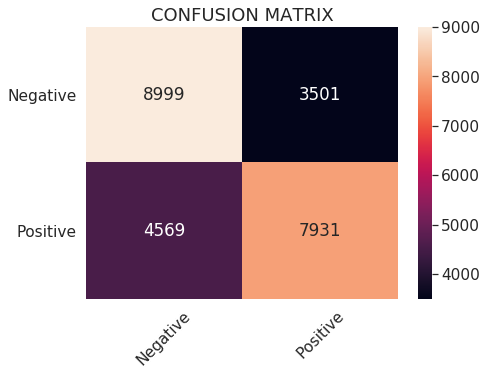

In [58]:
# Printing the Confusion Matrix with test Accuracy
df_cm = pd.DataFrame(cm, index = (0, 1), columns = (0, 1))
plt.figure(figsize = (7,5))
sns.set(font_scale=1.4)
sns.heatmap(df_cm, annot=True, fmt='g', xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
plt.xticks(rotation=45)
plt.yticks(rotation='horizontal')
plt.title("CONFUSION MATRIX", fontsize= 18)
print("Test Data Accuracy: %0.4f" % accuracy_score(y_test, y_pred))

In [59]:
# Applying k-Fold Cross Validation
from sklearn.model_selection import cross_val_score
accuracies = cross_val_score(estimator = classifier, X = X_train, y = y_train, cv = 10)
print("Gaussian NB: %0.3f (+/- %0.3f)" % (accuracies.mean(), accuracies.std() * 2))

Gaussian NB: 0.688 (+/- 0.018)


In [60]:
model_results = pd.DataFrame([['Naive Bayes Classifier', acc, precision, recall, f1, 
                         f"{accuracies.mean():.3f} ( +/- {(accuracies.std() * 2):.3f})"]],
               columns = ['Model', 'Accuracy', 'Precision', 'Recall', 'F1 Score', 
                          'GridSearch Accuracy Training Set (10 Folds)'])
results = results.append(model_results, ignore_index = True)
results

,Model,Accuracy,Precision,Recall,F1 Score,GridSearch Accuracy Training Set (10 Folds)
0,Logistic Regression,0.83852,0.838006,0.83928,0.838643,0.842 ( +/- 0.009)
1,Naive Bayes Classifier,0.67720,0.693754,0.63448,0.662795,0.688 ( +/- 0.018)


# SGD Classifier

In [61]:
from sklearn.linear_model import SGDClassifier
classifier = SGDClassifier(max_iter=500, tol=1e-3)
classifier.fit(X_train, y_train)

SGDClassifier(alpha=0.0001, average=False, class_weight=None,
              early_stopping=False, epsilon=0.1, eta0=0.0, fit_intercept=True,
              l1_ratio=0.15, learning_rate='optimal', loss='hinge',
              max_iter=500, n_iter_no_change=5, n_jobs=None, penalty='l2',
              power_t=0.5, random_state=None, shuffle=True, tol=0.001,
              validation_fraction=0.1, verbose=0, warm_start=False)

In [0]:
# Predicting Test Set
y_pred = classifier.predict(X_test)

In [63]:
# Evaluating Results
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, precision_score, recall_score
cm = confusion_matrix(y_test, y_pred)
acc= accuracy_score(y_test, y_pred)
precision= precision_score(y_test, y_pred) # tp / (tp + fp)
recall= recall_score(y_test, y_pred) # tp / (tp + fn)
f1= f1_score(y_test, y_pred)
print(f"Accuracy : {(acc * 100):.4f} %")

Accuracy : 82.6680 %


Test Data Accuracy: 0.8267


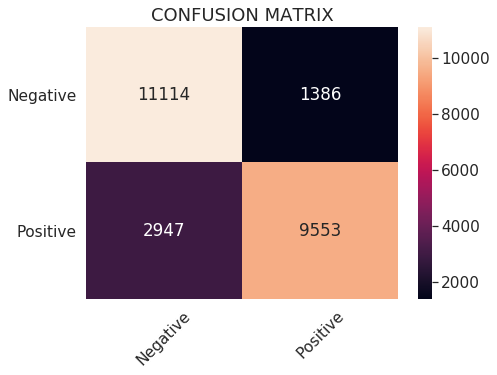

In [64]:
# Printing the Confusion Matrix with test Accuracy
df_cm = pd.DataFrame(cm, index = (0, 1), columns = (0, 1))
plt.figure(figsize = (7,5))
sns.set(font_scale=1.4)
sns.heatmap(df_cm, annot=True, fmt='g', xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
plt.xticks(rotation=45)
plt.yticks(rotation='horizontal')
plt.title("CONFUSION MATRIX", fontsize= 18)
print("Test Data Accuracy: %0.4f" % accuracy_score(y_test, y_pred))

In [65]:
# Applying k-Fold Cross Validation
from sklearn.model_selection import cross_val_score
accuracies = cross_val_score(estimator = classifier, X = X_train, y = y_train, cv = 10)
print("SGD Classifier: %0.3f (+/- %0.3f)" % (accuracies.mean(), accuracies.std() * 2))

SGD Classifier: 0.838 (+/- 0.015)


In [66]:
model_results = pd.DataFrame([['SGD Classifier', acc, precision, recall, f1, 
                         f"{accuracies.mean():.3f} ( +/- {(accuracies.std() * 2):.3f})"]],
               columns = ['Model', 'Accuracy', 'Precision', 'Recall', 'F1 Score', 
                          'GridSearch Accuracy Training Set (10 Folds)'])
results = results.append(model_results, ignore_index = True)
results

,Model,Accuracy,Precision,Recall,F1 Score,GridSearch Accuracy Training Set (10 Folds)
0,Logistic Regression,0.83852,0.838006,0.83928,0.838643,0.842 ( +/- 0.009)
1,Naive Bayes Classifier,0.67720,0.693754,0.63448,0.662795,0.688 ( +/- 0.018)
2,SGD Classifier,0.82668,0.873297,0.76424,0.815137,0.838 ( +/- 0.015)
